# QUESTION 5 — LE SPECTATEUR CONSOMMERA-T-IL AU BAR ?

**Objectif :** Prédire si un spectateur consommera au bar à partir des informations disponibles au moment de l'achat de son billet.

**Méthode :** Classification supervisée — K-Nearest Neighbors (KNN)

### 1. Chargement des données

In [1]:
#importation des bibliothèques

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Chargement des données nettoyées

billets = pd.read_csv("../data/processed/billets_clean.csv")
evenements = pd.read_csv("../data/processed/evenements_clean.csv",parse_dates=['date'])

# Vérification des dimensions

print("billets:",billets.shape)
print("evenements:",evenements.shape)

# Aperçu des données

billets.head()



billets: (700, 15)
evenements: (96, 9)


,billet_id,evenement_id,zone,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age,deja_venu,revient_saison_suivante,age_inconnu,prix_plancher,invitation
0,BL600680,EV369,loge,73.66,53.0,23.0,16.6,-13.5,28.63,41.0,False,True,False,False,False
1,BL600471,EV386,fosse,122.64,44.0,56.0,0.7,-1.7,10.63,44.0,False,False,False,False,False
2,BL600421,EV313,gradin bas,59.81,29.0,34.0,-10.3,-21.7,3.01,32.0,False,False,False,False,False
3,BL600643,EV342,gradin bas,86.22,33.0,32.0,12.9,21.4,4.71,42.0,False,False,False,False,False
4,BL600447,EV388,gradin haut,67.45,102.0,81.0,-35.3,42.9,NaN,30.0,True,True,False,False,False


### 1.1 Vérification de la structure des données

In [2]:
# Informations générales sur les billets
billets.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   billet_id                700 non-null    str    
 1   evenement_id             700 non-null    str    
 2   zone                     700 non-null    str    
 3   prix_paye_eur            700 non-null    float64
 4   achat_jours_avant        700 non-null    float64
 5   arrivee_min_avant        700 non-null    float64
 6   x_salle_m                700 non-null    float64
 7   y_salle_m                700 non-null    float64
 8   conso_bar_eur            686 non-null    float64
 9   age                      700 non-null    float64
 10  deja_venu                700 non-null    bool   
 11  revient_saison_suivante  700 non-null    bool   
 12  age_inconnu              700 non-null    bool   
 13  prix_plancher            700 non-null    bool   
 14  invitation               700 non-null

### 2. Définition de la variable cible

La question 5 est un problème de classification binaire.
À partir de la variable `conso_bar_eur`, nous définissons
une nouvelle variable cible `conso_bar` :

- 0 : le spectateur ne consomme pas au bar.
- 1 : le spectateur consomme au bar.

Les observations dont la consommation au bar est inconnue
sont exclues de l'apprentissage et de l'évaluation du modèle
afin d'éviter l'attribution artificielle d'une classe.

Cette opération concerne 14 billets sur 700 (2 %).

### 2.1 Traitement des valeurs manquantes de consommation au bar

In [3]:
# Nombre de valeurs manquantes avant

print("Consommations inconnues avant :", billets['conso_bar_eur'].isnull().sum())

# Copie sans les billets dont la consommation est inconnue
# (un NaN n'est pas un 0 : décision de l'audit)

billets_q5 = billets.dropna(subset=['conso_bar_eur']).copy()

# Vérifications après suppression

print("Consommations inconnues après :", billets_q5['conso_bar_eur'].isnull().sum())  
print("Nombre de billets :", len(billets_q5))                                         

Consommations inconnues avant : 14
Consommations inconnues après : 0
Nombre de billets : 686


### 2.2 Création de la variable cible binaire

In [4]:
# Création de la variable cible binaire

billets_q5['conso_bar'] = (billets_q5['conso_bar_eur']>0).astype(int)

# Vérification de la variable cible

billets_q5[['conso_bar_eur','conso_bar']].head(10)

,conso_bar_eur,conso_bar
0,28.63,1
1,10.63,1
2,3.01,1
3,4.71,1
5,12.61,1
6,12.38,1
7,7.47,1
8,0.00,0
9,8.07,1
10,7.01,1


### 2.3 Analyse de la distribution de la variable cible

In [5]:
# Nombre de consommateurs et de non-consommateurs

effectifs = billets_q5['conso_bar'].value_counts().sort_index()

# Pourcentage de chaque classe

Pourcentage = billets_q5['conso_bar'].value_counts(normalize=True).sort_index() *100

# Création d'un tableau récapitulatif

distribution=pd.DataFrame({
    'effectifs':effectifs,
    'Pourcentage (%)':Pourcentage.round(2)
})
display(distribution)



,effectifs,Pourcentage (%)
conso_bar,,
0,72,10.5
1,614,89.5


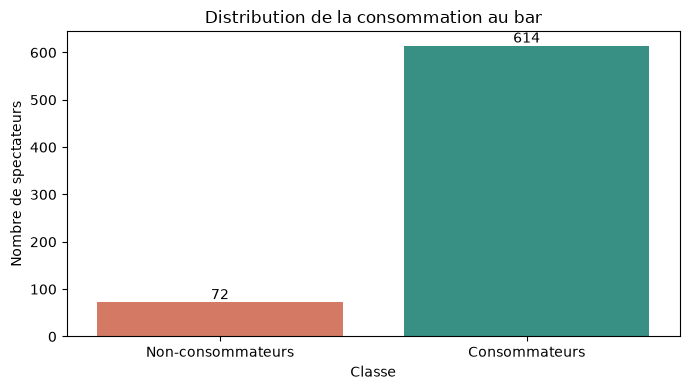

In [6]:
# Visualisation de la distribution des classes
plt.figure(figsize=(7, 4))

ax = sns.countplot(
    data=billets_q5,
    x='conso_bar',
    hue='conso_bar',
    palette=['#E76F51', '#2A9D8F'],
    legend=False
)

# Affichage des effectifs sur les barres
for container in ax.containers:
    ax.bar_label(container)

plt.title('Distribution de la consommation au bar')
plt.xticks([0, 1], ['Non-consommateurs', 'Consommateurs'])
plt.xlabel('Classe')
plt.ylabel('Nombre de spectateurs')
plt.tight_layout()
plt.show()

**Interprétation :**

La distribution de la variable cible révèle un déséquilibre
important entre les deux classes :

- Classe 0 : 72 non-consommateurs (10,50 %).
- Classe 1 : 614 consommateurs (89,50 %).

Ce déséquilibre peut favoriser la classe majoritaire lors
de l'apprentissage du modèle KNN. L'accuracy seule ne sera
donc pas suffisante pour évaluer ses performances.

Nous utiliserons notamment la précision, le rappel,
le F1-score et la matrice de confusion.

### 3. Sélection des variables prédictives

La sélection des variables repose sur les informations
disponibles au moment de l'achat du billet afin d'éviter
toute fuite de données (Data Leakage).

### 3.1 Analyse des variables événementielles

In [7]:
# Informations générales sur les événements
evenements.info()

# Aperçu des données événementielles
display(evenements.head())

<class 'pandas.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   evenement_id       96 non-null     str           
 1   genre              96 non-null     str           
 2   jour_semaine       96 non-null     str           
 3   capacite           96 non-null     int64         
 4   prix_moyen_eur     96 non-null     float64       
 5   notoriete_artiste  96 non-null     float64       
 6   billets_vendus     93 non-null     float64       
 7   date               96 non-null     datetime64[us]
 8   taux_remplissage   93 non-null     float64       
dtypes: datetime64[us](1), float64(4), int64(1), str(3)
memory usage: 6.9 KB


,evenement_id,genre,jour_semaine,capacite,prix_moyen_eur,notoriete_artiste,billets_vendus,date,taux_remplissage
0,EV320,rap,dim,9800,18.00,26.0,4923.0,2025-11-20,0.502347
1,EV370,spectacle,mar,15800,74.23,20.0,6051.0,2026-06-08,0.382975
2,EV377,sport,sam,6500,45.99,53.0,5221.0,2026-07-06,0.803231
3,EV362,rap,ven,9800,70.96,41.0,6203.0,2026-05-07,0.632959
4,EV394,sport,dim,9800,46.33,100.0,7196.0,2026-09-12,0.734286


### 3.1.1 Vérification de la cohérence des données temporelles

In [8]:
# Calcul du jour à partir de la date
jours_calcules = evenements['date'].dt.day_name().map({
    'Monday': 'lun',
    'Tuesday': 'mar',
    'Wednesday': 'mer',
    'Thursday': 'jeu',
    'Friday': 'ven',
    'Saturday': 'sam',
    'Sunday': 'dim'
})
# Vérification des incohérences
incoherences = evenements['jour_semaine'] != jours_calcules

print("Nombre d'incohérences :", incoherences.sum())
print("Nombre d'événements :", len(evenements))

Nombre d'incohérences : 79
Nombre d'événements : 96


**Interprétation :**

La vérification révèle 79 incohérences sur 96 événements
(82,29 %) entre la date et le jour de la semaine renseigné.

Conformément aux conclusions de l'audit général du projet,
la variable `jour_semaine` est privilégiée en raison de
sa répartition plus réaliste pour une salle de spectacle.

Nous allons étudier sa pertinence pour la prédiction
de la consommation au bar avant de décider de son
intégration au modèle KNN.

### 3.2 Jointure des billets et des événements

La jointure permet d'enrichir les données des billets
avec les caractéristiques des événements, en utilisant
la clé commune `evenement_id`.

Seules les informations supposées disponibles au moment
de l'achat sont retenues afin d'éviter les fuites de données.

In [9]:
# Sélection des variables événementielles
variables_evenements = [
    'evenement_id',
    'genre',
    'jour_semaine',
    'capacite',
    'notoriete_artiste'
]

# Jointure des deux DataFrames
donnees_q5 = billets_q5.merge(
    evenements[variables_evenements],
    on='evenement_id',
    how='left',
    validate='many_to_one'
)

# Vérification des dimensions
print("Dimensions avant jointure :", billets_q5.shape)
print("Dimensions après jointure :", donnees_q5.shape)

# Aperçu des données fusionnées
display(donnees_q5.head())

Dimensions avant jointure : (686, 16)
Dimensions après jointure : (686, 20)


,billet_id,evenement_id,zone,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age,deja_venu,revient_saison_suivante,age_inconnu,prix_plancher,invitation,conso_bar,genre,jour_semaine,capacite,notoriete_artiste
0,BL600680,EV369,loge,73.66,53.0,23.0,16.6,-13.5,28.63,41.0,False,True,False,False,False,1,rock,ven,9800,22.0
1,BL600471,EV386,fosse,122.64,44.0,56.0,0.7,-1.7,10.63,44.0,False,False,False,False,False,1,rock,sam,9800,94.0
2,BL600421,EV313,gradin bas,59.81,29.0,34.0,-10.3,-21.7,3.01,32.0,False,False,False,False,False,1,rock,dim,9800,7.0
3,BL600643,EV342,gradin bas,86.22,33.0,32.0,12.9,21.4,4.71,42.0,False,False,False,False,False,1,concert pop,dim,15800,22.0
4,BL600127,EV300,fosse,64.94,92.0,39.0,-5.9,-15.4,12.61,35.0,True,True,True,False,False,1,rock,jeu,9800,45.0


### 3.2.1 Vérification de la jointure

In [10]:
# Vérification des valeurs manquantes après la jointure
donnees_q5[variables_evenements].isnull().sum()

evenement_id         0
genre                0
jour_semaine         0
capacite             0
notoriete_artiste    0
dtype: int64

**Interprétation :**

La jointure a permis d'enrichir les 686 billets avec quatre
variables événementielles, sans perte ni duplication
d'observations et sans introduction de valeurs manquantes
dans les variables ajoutées.

### 3.2.2 Analyse de la consommation au bar selon le jour de la semaine

In [11]:
# Analyse de la consommation au bar selon le jour
conso_par_jour = donnees_q5.groupby('jour_semaine')['conso_bar'].agg(
    ['count', 'sum', 'mean']
)

# Renommage des colonnes
conso_par_jour.columns = [
    'Nombre de billets',
    'Nombre de consommateurs',
    'Taux de consommation (%)'
]

# Conversion du taux en pourcentage
conso_par_jour['Taux de consommation (%)'] *= 100

# Affichage des résultats
display(conso_par_jour.round(2))

,Nombre de billets,Nombre de consommateurs,Taux de consommation (%)
jour_semaine,,,
dim,70,60,85.71
jeu,126,106,84.13
mar,49,46,93.88
mer,82,75,91.46
sam,221,202,91.40
ven,138,125,90.58


**Interprétation :**

Le taux de consommation au bar varie entre 84,13 %
le jeudi et 93,88 % le mardi, soit un écart de
9,75 points de pourcentage.

Toutefois, le taux élevé du mardi doit être interprété
avec prudence en raison de son faible effectif
(49 billets).

Ces résultats suggèrent un intérêt prédictif potentiel
de la variable `jour_semaine`. Elle est donc retenue
provisoirement, puis son utilité sera évaluée en comparant
les performances du KNN avec et sans cette variable
par validation croisée.

### 3.3 Sélection et justification des variables prédictives

Les variables prédictives sont sélectionnées selon leur
pertinence pour la consommation au bar et leur disponibilité
au moment de l'achat du billet.

Les identifiants, les informations futures et les variables
susceptibles de provoquer une fuite de données sont exclus.
Une première sélection limite également les variables
potentiellement redondantes.

In [12]:
# Variables prédictives numériques
variables_numeriques = [
    'prix_paye_eur',
    'achat_jours_avant',
    'age',
    'notoriete_artiste'
]

# Variables prédictives catégorielles
variables_categorielles = [
    'zone',
    'genre',
    'jour_semaine',
    'capacite'
]

# Variables prédictives booléennes
variables_booleennes = [
    'deja_venu',
    'invitation'
]

# Regroupement des variables prédictives
variables_predictives = (
    variables_numeriques
    + variables_categorielles
    + variables_booleennes
)

# Vérification des variables sélectionnées
print("Nombre de variables numériques :", len(variables_numeriques))
print("Nombre de variables catégorielles :", len(variables_categorielles))
print("Nombre de variables booléennes :", len(variables_booleennes))
print("Nombre total de variables prédictives :", len(variables_predictives))

display(donnees_q5[variables_predictives].head())

Nombre de variables numériques : 4
Nombre de variables catégorielles : 4
Nombre de variables booléennes : 2
Nombre total de variables prédictives : 10


,prix_paye_eur,achat_jours_avant,age,notoriete_artiste,zone,genre,jour_semaine,capacite,deja_venu,invitation
0,73.66,53.0,41.0,22.0,loge,rock,ven,9800,False,False
1,122.64,44.0,44.0,94.0,fosse,rock,sam,9800,False,False
2,59.81,29.0,32.0,7.0,gradin bas,rock,dim,9800,False,False
3,86.22,33.0,42.0,22.0,gradin bas,concert pop,dim,15800,False,False
4,64.94,92.0,35.0,45.0,fosse,rock,jeu,9800,True,False


La variable `capacite` est traitée comme une variable
catégorielle, car elle représente trois configurations
distinctes de la salle (6 500, 9 800 et 15 800 places),
conformément aux conclusions de l'audit général.

### 4. Définition des variables X et y

- X : ensemble des variables prédictives sélectionnées.
- y : variable cible binaire `conso_bar` à prédire.

In [13]:
# Définition des variables prédictives
X = donnees_q5[variables_predictives].copy()

# Définition de la variable cible
y = donnees_q5['conso_bar'].copy()

# Vérification des dimensions
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (686, 10)
Dimensions de y : (686,)


### 4.1 Vérification des données avant l'apprentissage

In [14]:
# Vérification des valeurs manquantes dans X
print("Valeurs manquantes dans X :", X.isnull().sum().sum())

# Vérification des valeurs manquantes dans y
print("Valeurs manquantes dans y :", y.isnull().sum())

# Vérification des classes de la variable cible
print("Classes de y :", sorted(y.unique().tolist()))

Valeurs manquantes dans X : 0
Valeurs manquantes dans y : 0
Classes de y : [0, 1]


### 5. Séparation des données d'entraînement et de test

Les données sont réparties en deux ensembles :

- 80 % pour l'entraînement du modèle.
- 20 % pour l'évaluation finale.

Une séparation stratifiée est utilisée afin de préserver
la proportion des classes dans les deux ensembles,
compte tenu du déséquilibre de la variable cible.

In [15]:
# Importation de la fonction de séparation des données
from sklearn.model_selection import train_test_split

# Séparation des données d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Vérification des dimensions
print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test :", X_test.shape)
print("Dimensions de y_train :", y_train.shape)
print("Dimensions de y_test :", y_test.shape)

Dimensions de X_train : (548, 10)
Dimensions de X_test : (138, 10)
Dimensions de y_train : (548,)
Dimensions de y_test : (138,)


### 5.1 Vérification de la répartition des classes

In [16]:
# Comparaison de la distribution des classes
distribution_classes = pd.DataFrame({
    'Ensemble initial (%)': y.value_counts(normalize=True) * 100,
    'Entraînement (%)': y_train.value_counts(normalize=True) * 100,
    'Test (%)': y_test.value_counts(normalize=True) * 100
}).sort_index()

# Affichage des résultats
display(distribution_classes.round(2))

,Ensemble initial (%),Entraînement (%),Test (%)
conso_bar,,,
0,10.5,10.58,10.14
1,89.5,89.42,89.86


**Interprétation :**

La séparation stratifiée permet de conserver des proportions
de classes similaires dans les ensembles d'entraînement
et de test.

Le déséquilibre initial est préservé, avec environ 90 %
de consommateurs et 10 % de non-consommateurs.

### 6. Encodage et standardisation des variables

Le modèle KNN repose sur le calcul des distances entre
les observations. Il est donc nécessaire de standardiser
les variables numériques et d'encoder les variables
catégorielles afin de rendre les données exploitables
par le modèle.

### 6.1 Standardisation des variables numériques

La standardisation avec `StandardScaler` permet de centrer
les variables numériques et de réduire les différences
d'échelle afin d'éviter qu'une variable ne domine le calcul
des distances du KNN.

Les paramètres de standardisation sont calculés uniquement
à partir des données d'entraînement.

In [17]:
# Importation de StandardScaler
from sklearn.preprocessing import StandardScaler

# Initialisation du standardiseur
scaler = StandardScaler()

# Standardisation des variables numériques d'entraînement
X_train_num = scaler.fit_transform(
    X_train[variables_numeriques]
)

# Standardisation des variables numériques de test
X_test_num = scaler.transform(
    X_test[variables_numeriques]
)

# Conversion des résultats en DataFrames
X_train_num = pd.DataFrame(
    X_train_num,
    columns=variables_numeriques,
    index=X_train.index
)

X_test_num = pd.DataFrame(
    X_test_num,
    columns=variables_numeriques,
    index=X_test.index
)

# Aperçu des données standardisées
print("Données d'entraînement :")
display(X_train_num.head())

print("Données de test :")
display(X_test_num.head())

Données d'entraînement :


,prix_paye_eur,achat_jours_avant,age,notoriete_artiste
162,0.369381,-0.749965,-1.375606,-0.288233
231,-0.433161,-0.749965,0.743636,-1.123403
338,0.640315,-1.247400,-0.492588,0.720931
437,0.599595,-0.849452,-1.199003,-1.019007
412,-0.514281,0.410717,-1.375606,0.024956


Données de test :


,prix_paye_eur,achat_jours_avant,age,notoriete_artiste
173,-0.857357,-1.181075,1.096843,0.546938
584,-1.346962,-0.352017,0.920240,0.546938
128,0.348219,-0.683640,1.273447,-0.775416
679,-1.597375,1.239775,0.037222,1.938888
588,0.219325,-0.915776,-0.051080,-0.114239


### 6.1.1 Vérification de la standardisation

In [18]:
# Comparaison statistique avant et après standardisation
verification_standardisation = pd.DataFrame({
    'Moyenne avant (Train)': X_train[variables_numeriques].mean(),
    'Écart-type avant (Train)': X_train[variables_numeriques].std(ddof=0),
    'Moyenne après (Train)': X_train_num.mean(),
    'Écart-type après (Train)': X_train_num.std(ddof=0),
    'Moyenne après (Test)': X_test_num.mean(),
    'Écart-type après (Test)': X_test_num.std(ddof=0)
})

display(verification_standardisation.round(4))

,Moyenne avant (Train),Écart-type avant (Train),Moyenne après (Train),Écart-type après (Train),Moyenne après (Test),Écart-type après (Test)
prix_paye_eur,70.3296,31.1884,0.0,1.0,-0.0897,0.9080
achat_jours_avant,41.6150,30.1547,0.0,1.0,0.0164,1.1223
age,35.5785,11.3248,0.0,1.0,0.0603,1.0881
notoriete_artiste,44.2828,28.7366,-0.0,1.0,-0.0283,0.9937


**Interprétation :**

Après standardisation, les variables numériques du jeu
d'entraînement présentent une moyenne proche de 0 et
un écart-type égal à 1.

Les données de test sont transformées à partir des paramètres
calculés sur le jeu d'entraînement, ce qui explique les
légères différences observées.

Cette démarche réduit les différences d'échelle entre
les variables numériques tout en évitant les fuites de
données liées à la standardisation.

### 6.2 Encodage des variables catégorielles

L'encodage One-Hot permet de transformer les variables
catégorielles en colonnes binaires sans introduire
d'ordre artificiel entre les modalités.

L'encodeur est ajusté uniquement sur les données
d'entraînement, puis appliqué aux données de test.

In [19]:
# Importation de OneHotEncoder
from sklearn.preprocessing import OneHotEncoder

# Initialisation de l'encodeur
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Encodage des variables catégorielles d'entraînement
X_train_cat = encoder.fit_transform(
    X_train[variables_categorielles]
)

# Encodage des variables catégorielles de test
X_test_cat = encoder.transform(
    X_test[variables_categorielles]
)

# Récupération des noms des nouvelles colonnes
colonnes_encodees = encoder.get_feature_names_out(
    variables_categorielles
)

# Conversion des résultats en DataFrames
X_train_cat = pd.DataFrame(
    X_train_cat,
    columns=colonnes_encodees,
    index=X_train.index
)

X_test_cat = pd.DataFrame(
    X_test_cat,
    columns=colonnes_encodees,
    index=X_test.index
)

# Aperçu des données encodées
print("Données d'entraînement :")
display(X_train_cat.head())

print("Données de test :")
display(X_test_cat.head())

Données d'entraînement :


,zone_fosse,zone_gradin bas,zone_gradin haut,zone_loge,genre_concert pop,genre_humour,genre_rap,genre_rock,genre_spectacle,genre_sport,jour_semaine_dim,jour_semaine_jeu,jour_semaine_mar,jour_semaine_mer,jour_semaine_sam,jour_semaine_ven,capacite_6500,capacite_9800,capacite_15800
162,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
231,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
338,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
437,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
412,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


Données de test :


,zone_fosse,zone_gradin bas,zone_gradin haut,zone_loge,genre_concert pop,genre_humour,genre_rap,genre_rock,genre_spectacle,genre_sport,jour_semaine_dim,jour_semaine_jeu,jour_semaine_mar,jour_semaine_mer,jour_semaine_sam,jour_semaine_ven,capacite_6500,capacite_9800,capacite_15800
173,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
584,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
128,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
679,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
588,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


### 6.2.1 Vérification de l'encodage

In [20]:
# Nombre de catégories pour chaque variable
for variable, categories in zip(
    variables_categorielles, encoder.categories_
):
    print(variable, ":", len(categories), "catégories")
    print("Modalités :", categories.tolist())
    print()

# Vérification des dimensions après encodage
print("Dimensions avant encodage (Train) :",
      X_train[variables_categorielles].shape)

print("Dimensions après encodage (Train) :", X_train_cat.shape)

print("Dimensions avant encodage (Test) :",
      X_test[variables_categorielles].shape)

print("Dimensions après encodage (Test) :", X_test_cat.shape)

# Vérification de la correspondance des colonnes
print("Colonnes identiques :", 
      X_train_cat.columns.equals(X_test_cat.columns))

zone : 4 catégories
Modalités : ['fosse', 'gradin bas', 'gradin haut', 'loge']

genre : 6 catégories
Modalités : ['concert pop', 'humour', 'rap', 'rock', 'spectacle', 'sport']

jour_semaine : 6 catégories
Modalités : ['dim', 'jeu', 'mar', 'mer', 'sam', 'ven']

capacite : 3 catégories
Modalités : [6500, 9800, 15800]

Dimensions avant encodage (Train) : (548, 4)
Dimensions après encodage (Train) : (548, 19)
Dimensions avant encodage (Test) : (138, 4)
Dimensions après encodage (Test) : (138, 19)
Colonnes identiques : True


**Interprétation :**

L'encodage One-Hot transforme les quatre variables
catégorielles en 19 colonnes binaires.

Les ensembles d'entraînement et de test possèdent
les mêmes colonnes, dans le même ordre, sans perte
d'observations.

Cette transformation permet au KNN d'exploiter les
variables catégorielles sans introduire d'ordre
artificiel entre leurs modalités.

### 6.3 Traitement des variables booléennes

Les variables booléennes sont converties en valeurs
binaires (0 et 1) afin d'être directement exploitables
dans le calcul des distances du KNN.

In [21]:
# Conversion des variables booléennes d'entraînement
X_train_bool = X_train[variables_booleennes].astype(int)

# Conversion des variables booléennes de test
X_test_bool = X_test[variables_booleennes].astype(int)

# Aperçu des données transformées
print("Données d'entraînement :")
display(X_train_bool.head())

print("Données de test :")
display(X_test_bool.head())

# Vérification des dimensions
print("Dimensions de X_train_bool :", X_train_bool.shape)
print("Dimensions de X_test_bool :", X_test_bool.shape)

Données d'entraînement :


,deja_venu,invitation
162,0,0
231,0,0
338,0,0
437,0,0
412,0,0


Données de test :


,deja_venu,invitation
173,0,0
584,1,0
128,0,0
679,0,0
588,1,0


Dimensions de X_train_bool : (548, 2)
Dimensions de X_test_bool : (138, 2)


### 6.4 Construction du ColumnTransformer

Le `ColumnTransformer` permet d'appliquer automatiquement
un traitement adapté à chaque type de variable :

- StandardScaler pour les variables numériques.
- OneHotEncoder pour les variables catégorielles.
- Conservation des variables booléennes sous forme binaire.

Cette approche centralise le prétraitement et facilite
son intégration dans le pipeline du modèle KNN.

In [22]:
# Importation de ColumnTransformer
from sklearn.compose import ColumnTransformer

# Construction du prétraitement
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), variables_numeriques),
        ('cat', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ), variables_categorielles),
        ('bool', 'passthrough', variables_booleennes)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

### 6.4.1 Application du prétraitement aux données Train et Test

In [23]:
# Prétraitement des données d'entraînement
X_train_prepared = preprocessor.fit_transform(X_train)

# Prétraitement des données de test
X_test_prepared = preprocessor.transform(X_test)

# Récupération des noms des colonnes
colonnes_finales = preprocessor.get_feature_names_out()

# Conversion en DataFrames
X_train_prepared = pd.DataFrame(
    X_train_prepared,
    columns=colonnes_finales,
    index=X_train.index
)

X_test_prepared = pd.DataFrame(
    X_test_prepared,
    columns=colonnes_finales,
    index=X_test.index
)

# Vérification des dimensions
print("Dimensions avant prétraitement (Train) :", X_train.shape)
print("Dimensions après prétraitement (Train) :", X_train_prepared.shape)

print("Dimensions avant prétraitement (Test) :", X_test.shape)
print("Dimensions après prétraitement (Test) :", X_test_prepared.shape)

# Aperçu des données préparées
display(X_train_prepared.head())
display(X_test_prepared.head())

Dimensions avant prétraitement (Train) : (548, 10)
Dimensions après prétraitement (Train) : (548, 25)
Dimensions avant prétraitement (Test) : (138, 10)
Dimensions après prétraitement (Test) : (138, 25)


,prix_paye_eur,achat_jours_avant,age,notoriete_artiste,zone_fosse,zone_gradin bas,zone_gradin haut,zone_loge,genre_concert pop,genre_humour,...,jour_semaine_jeu,jour_semaine_mar,jour_semaine_mer,jour_semaine_sam,jour_semaine_ven,capacite_6500,capacite_9800,capacite_15800,deja_venu,invitation
162,0.369381,-0.749965,-1.375606,-0.288233,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
231,-0.433161,-0.749965,0.743636,-1.123403,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
338,0.640315,-1.247400,-0.492588,0.720931,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
437,0.599595,-0.849452,-1.199003,-1.019007,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
412,-0.514281,0.410717,-1.375606,0.024956,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


,prix_paye_eur,achat_jours_avant,age,notoriete_artiste,zone_fosse,zone_gradin bas,zone_gradin haut,zone_loge,genre_concert pop,genre_humour,...,jour_semaine_jeu,jour_semaine_mar,jour_semaine_mer,jour_semaine_sam,jour_semaine_ven,capacite_6500,capacite_9800,capacite_15800,deja_venu,invitation
173,-0.857357,-1.181075,1.096843,0.546938,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
584,-1.346962,-0.352017,0.920240,0.546938,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
128,0.348219,-0.683640,1.273447,-0.775416,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
679,-1.597375,1.239775,0.037222,1.938888,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
588,0.219325,-0.915776,-0.051080,-0.114239,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


### 6.4.2 Vérification des données finales

In [24]:
# Vérification des valeurs manquantes
print("Valeurs manquantes (Train) :",
      X_train_prepared.isnull().sum().sum())

print("Valeurs manquantes (Test) :",
      X_test_prepared.isnull().sum().sum())

# Vérification des types numériques
print("Colonnes entièrement numériques (Train) :",
      X_train_prepared.select_dtypes(include='number').shape[1]
      == X_train_prepared.shape[1])

print("Colonnes entièrement numériques (Test) :",
      X_test_prepared.select_dtypes(include='number').shape[1]
      == X_test_prepared.shape[1])

# Vérification de la correspondance des colonnes
print("Colonnes identiques :",
      X_train_prepared.columns.equals(X_test_prepared.columns))

# Vérification de la correspondance entre X et y
print("Index de X et y identiques (Train) :",
      X_train_prepared.index.equals(y_train.index))

print("Index de X et y identiques (Test) :",
      X_test_prepared.index.equals(y_test.index))

Valeurs manquantes (Train) : 0
Valeurs manquantes (Test) : 0
Colonnes entièrement numériques (Train) : True
Colonnes entièrement numériques (Test) : True
Colonnes identiques : True
Index de X et y identiques (Train) : True
Index de X et y identiques (Test) : True


### 6.5 Intégration du prétraitement dans un Pipeline

Le Pipeline regroupe le prétraitement des données et
le modèle KNN dans une même chaîne de traitement.

Cette approche garantit que les paramètres du
prétraitement sont appris uniquement sur les données
d'entraînement de chaque pli lors de la validation
croisée et facilite la prédiction sur de nouvelles
observations.

In [25]:
# Importation des bibliothèques
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

# Construction du pipeline
pipeline_knn = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

# Affichage de la structure du pipeline
display(pipeline_knn)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_